In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np

from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde

# custom helper scripts
from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

In [2]:
data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicity = 0.2
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']


In [3]:
# hydrogen-poor/free stars

WR_types = []
time_array = []
weight_array = []
state_array = []
key_array = []
star_array = []  # Track whether entry is from S1 or S2
period_array = []
separation_array = []
Teff_array = []
L_array = []
optical_depth_array = []
surface_H_array = []
surface_He_array = []
mass_array = []
mass_companion_array = []
radius_array = []
Mdot_array = []
companion_array = []
S1_state_array = []
surface_C = []
optical_depth = []

for key in tqdm(S1_WR_data):
    data = S1_WR_data[key]['data']
    weights = S1_WR_data[key]['weights']
    optical_depth_array.extend(S1_WR_data[key]['optical_depth'])
    
    surface_H_array.extend(data['S1_surface_h1'].values)
    surface_He_array.extend(data['S1_surface_he4'].values)
    Teff = 10**calc_Teff(data['S1_log_L'], data['S1_log_R'])
         
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    S1_state_array.extend(data['S1_state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S1'] * len(data))  # Mark as S1
    Teff_array.extend(Teff)
    L_array.extend(10**data['S1_log_L'].values)
    mass_array.extend(data['S1_mass'].values)
    mass_companion_array.extend(data['S2_mass'].values)
    radius_array.extend(10**data['S1_log_R'].values)
    Mdot_array.extend(10**data['S1_lg_mdot'].values)
    companion_array.extend(data['S2_state'].values)
    
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S1_mass'].values,
                                         data['S2_mass'].values)
    
    separation_array.extend(sep)
    
    
for key in tqdm(S2_WR_data):
    data = S2_WR_data[key]['data']
    weights = S2_WR_data[key]['weights']
    optical_depth_array.extend(S2_WR_data[key]['optical_depth'])
    
    surface_H_array.extend(data['S2_surface_h1'].values)
    surface_He_array.extend(data['S2_surface_he4'].values)
    Teff = 10**calc_Teff(data['S2_log_L'], data['S2_log_R'])
    
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S2'] * len(data))  # Mark as S2
    Teff_array.extend(Teff)
    L_array.extend(10**data['S2_log_L'].values)
    mass_array.extend(data['S2_mass'].values)
    mass_companion_array.extend(data['S1_mass'].values)
    radius_array.extend(10**data['S2_log_R'].values)
    Mdot_array.extend(10**data['S2_lg_mdot'].values)
    companion_array.extend(data['S1_state'])
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S2_mass'].values,
                                         data['S1_mass'].values)
    S1_state_array.extend(data['S2_state'].values)
    separation_array.extend(sep)
    

WR_types = np.array(WR_types)
time_array = np.array(time_array)
weight_array = np.array(weight_array)
state_array = np.array(state_array)
key_array = np.array(key_array)
star_array = np.array(star_array)  # Convert to array
period_array = np.array(period_array)
separation_array = np.array(separation_array)
Teff_array = np.array(Teff_array)
L_array = np.array(L_array)
optical_depth_array = np.array(optical_depth_array)
surface_H_array = np.array(surface_H_array)
surface_He_array = np.array(surface_He_array)
mass_array = np.array(mass_array)
radius_array = np.array(radius_array)
Mdot_array = np.array(Mdot_array)
companion_array = np.array(companion_array)
mass_companion_array = np.array(mass_companion_array)

100%|██████████| 31411/31411 [00:19<00:00, 1638.84it/s]


In [4]:
mask_H_burning = np.char.find(S1_state_array, 'H_burning') != -1 

WNE = (surface_H_array <= 0.05) & (surface_He_array >= 0.7) & (optical_depth_array > 1.5)

In [5]:
binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')

In [6]:
from posydon.popsyn.synthetic_population import Population
import pandas as pd
population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2025_11_04/')
population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

pop = Population(str(population_file))

Missing ini parameter: metallicity


In [7]:
HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

# S1 interaction masks - only apply to S1 entries
S1_entries = (star_array == 'S1')
mask_stable = S1_entries & np.isin(key_array, np.array(list(S1_stable_indices)))
mask_unstable = S1_entries & np.isin(key_array, np.array(list(S1_unstable_indices)))
mask_reverse_stable = S1_entries & np.isin(key_array, np.array(list(S1_reverse_stable_indices)))
mask_no_MT = S1_entries & np.isin(key_array, np.array(list(S1_no_MT_indices)))


S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

# S2 interaction masks - only apply to S2 entries
S2_entries = (star_array == 'S2')
S2_mask_stable = S2_entries & np.isin(key_array, np.array(list(S2_stable_indices)))
S2_mask_unstable = S2_entries & np.isin(key_array, np.array(list(S2_unstable_indices)))
S2_mask_reverse_stable = S2_entries & np.isin(key_array, np.array(list(S2_reverse_stable_indices)))
S2_mask_no_MT = S2_entries & np.isin(key_array, np.array(list(S2_no_MT_indices)))

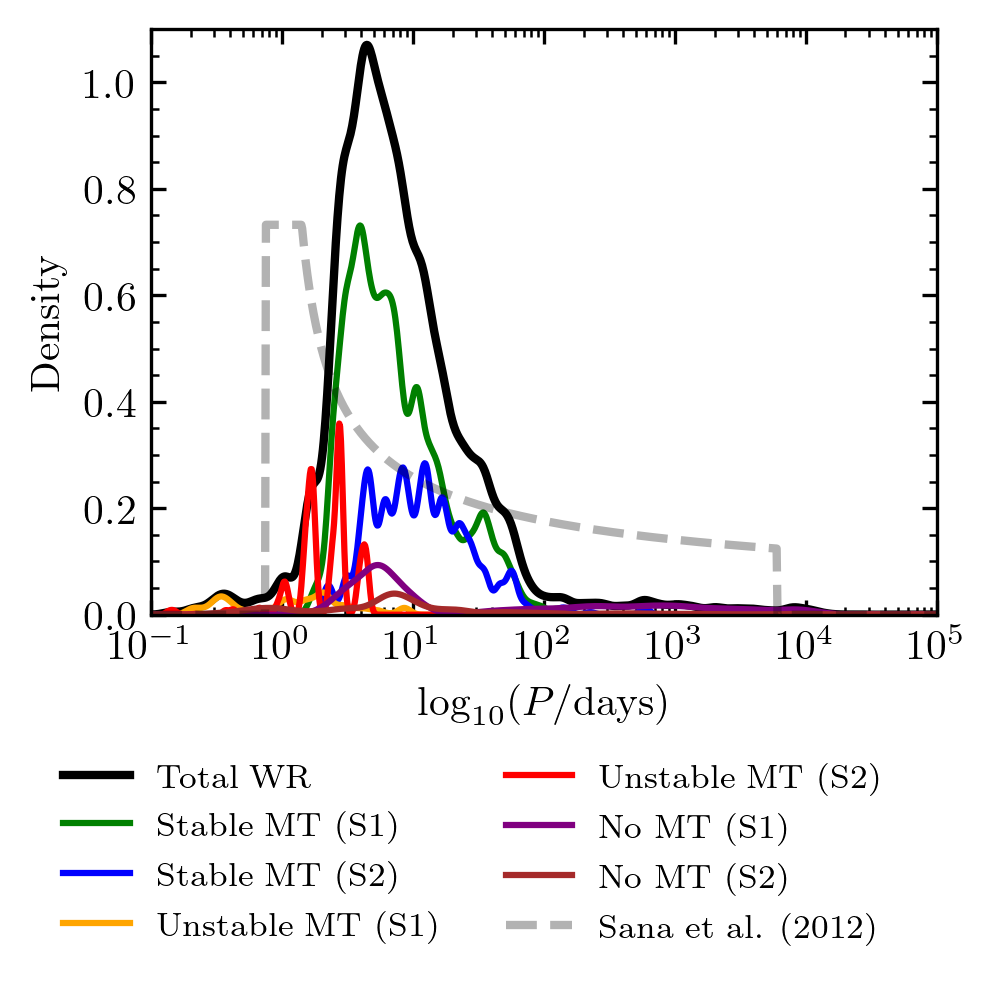

In [11]:
# Import Sana+12 period distribution
from posydon.popsyn.distributions import Sana12Period
from scipy.stats import gaussian_kde

mask = binary_mask & (WNE)

bw = 0.1


# Define common x_eval range for ALL KDEs
period_selection_all = period_array[mask]
x_eval = np.linspace(-1, np.log10(np.max(period_selection_all)), 1000)

# Total WR distribution (for reference)
period_selection = period_array[mask]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[mask], bw_method=bw)
kde_eval = kde(x_eval)
plt.plot(10**x_eval, kde_eval, color='black', label='Total WR', linewidth=2)

# Initialize sum
h = np.zeros_like(x_eval)

# S1 stable MT
period_selection = period_array[mask & (mask_stable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[mask & (mask_stable)], bw_method=bw)
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & (mask_stable)]) / np.sum(weight_array[mask])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='green', label='Stable MT (S1)')

# S2 stable MT
period_selection = period_array[mask & (S2_mask_stable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[mask & (S2_mask_stable)], bw_method=bw)
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & (S2_mask_stable)]) / np.sum(weight_array[mask])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='blue', label='Stable MT (S2)')

# unstable MT
period_selection = period_array[mask & (mask_unstable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[mask & (mask_unstable)], bw_method=bw)
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & (mask_unstable)]) / np.sum(weight_array[mask])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='orange', label='Unstable MT (S1)')

# unstable S2 MT
period_selection = period_array[mask & (S2_mask_unstable)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[mask & (S2_mask_unstable)], bw_method=bw)
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & (S2_mask_unstable)]) / np.sum(weight_array[mask])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='red', label='Unstable MT (S2)')

# no MT
period_selection = period_array[mask & (mask_no_MT)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[mask & (mask_no_MT)], bw_method=bw)
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & (mask_no_MT)]) / np.sum(weight_array[mask])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='purple', label='No MT (S1)')

# no MT S2
period_selection = period_array[mask & (S2_mask_no_MT)]
if len(period_selection) > 0:
    kde = gaussian_kde(np.log10(period_selection), weights=weight_array[mask & (S2_mask_no_MT)], bw_method=bw)
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & (S2_mask_no_MT)]) / np.sum(weight_array[mask])
    h += kde_eval * fraction
    plt.plot(10**x_eval, kde_eval*fraction, color='brown', label='No MT (S2)')

sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)
m_wr_progenitor = 20.0
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
plt.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.3, 
         label=f'Sana et al. (2012)')

plt.xscale('log')
plt.xlabel('$\log_{10}(P/\mathrm{days})$')
plt.ylabel('Density')
plt.ylim(0, 1.1)

plt.legend(bbox_to_anchor=(-0.15, -0.2), loc='upper left', ncol=2)
plt.xlim(1e-1,1e5)
plt.xticks([0.1, 1, 10, 100, 1000, 10000, 100000])

fig_path = '/Users/max/Documents/projects/WR_population/analysis/figures/'

plt.savefig(fig_path + 'png/SMC_WNE_formation_channels.png', bbox_inches='tight', dpi=300)
plt.savefig(fig_path + 'pdf/SMC_WNE_formation_channels.pdf', bbox_inches='tight')
plt.show()

# All systems initial conditions


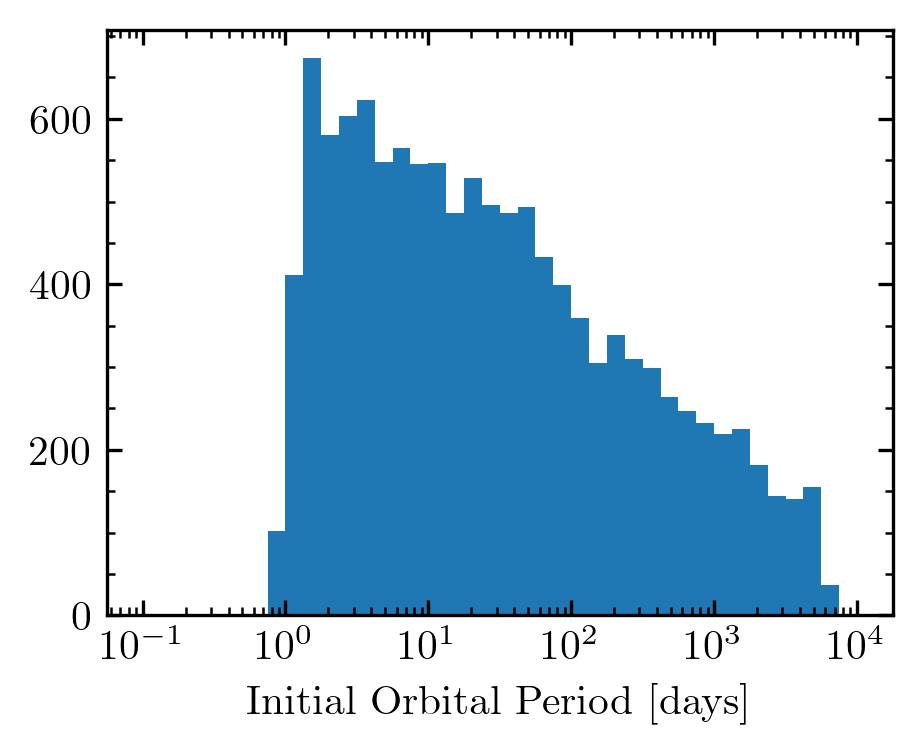

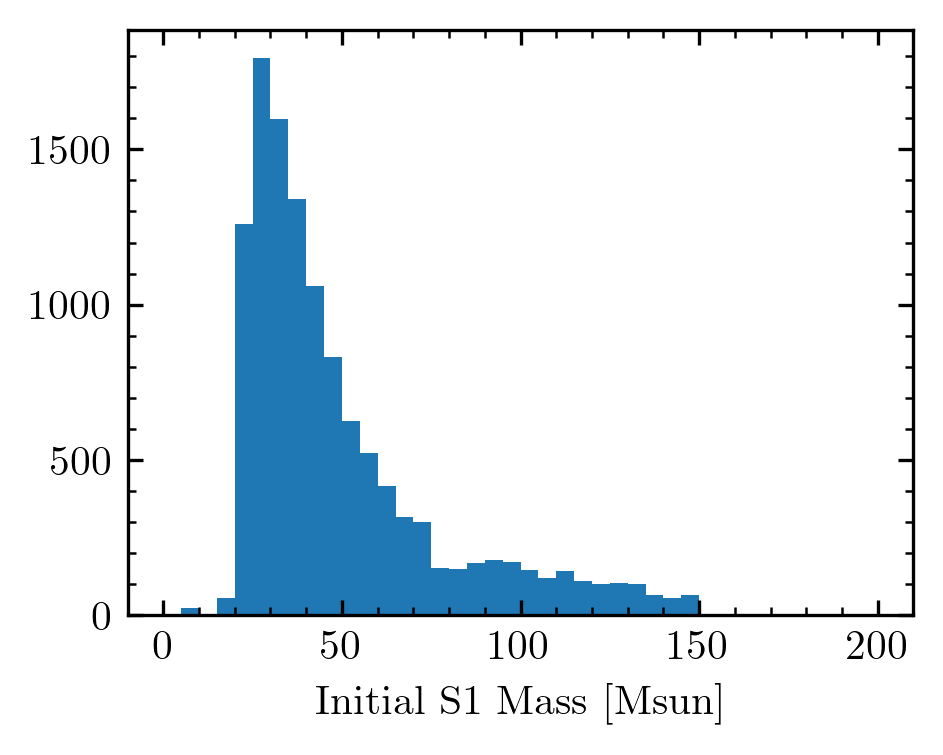

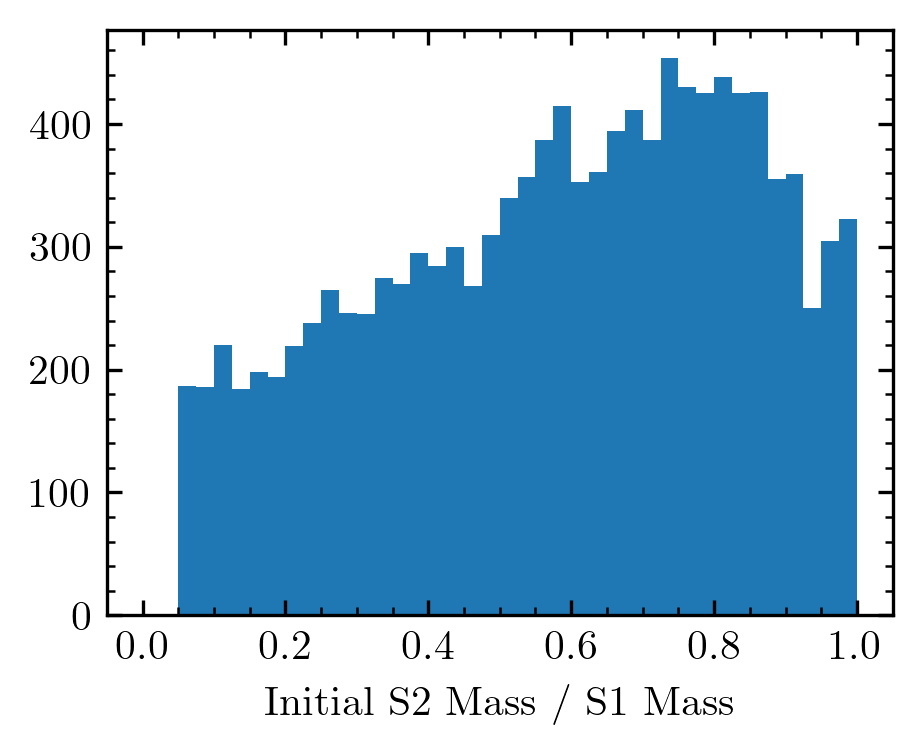

In [29]:
initial_condition = pop.oneline[np.unique(key_array[WNE & (mask_stable | mask_unstable | mask_no_MT)])]
# initial conditions

plt.hist(initial_condition['orbital_period_i'], bins=np.logspace(-1, 4, 41))
plt.xlabel('Initial Orbital Period [days]')
plt.xscale('log')
plt.show()

plt.hist(initial_condition['S1_mass_i'], bins=np.linspace(0, 200, 41))
plt.xlabel('Initial S1 Mass [Msun]')
plt.show()

plt.hist(initial_condition['S2_mass_i']/initial_condition['S1_mass_i'], bins=np.linspace(0, 1, 41))
plt.xlabel('Initial S2 Mass / S1 Mass')
plt.show()

## load 1Zsun HMS-HMS grid

In [30]:
from posydon.grids.psygrid import PSyGrid
from posydon.config import PATH_TO_POSYDON_DATA

grid = PSyGrid(PATH_TO_POSYDON_DATA + f'/HMS-HMS/{met_str}_Zsun.h5')


## Non-interacting systems

In [31]:
np.unique(key_array[mask_no_MT])

array([   18,    21,    65, ..., 99876, 99929, 99952])

In [32]:
initial_condition = pop.oneline[np.unique(key_array[mask_no_MT & WNE])]

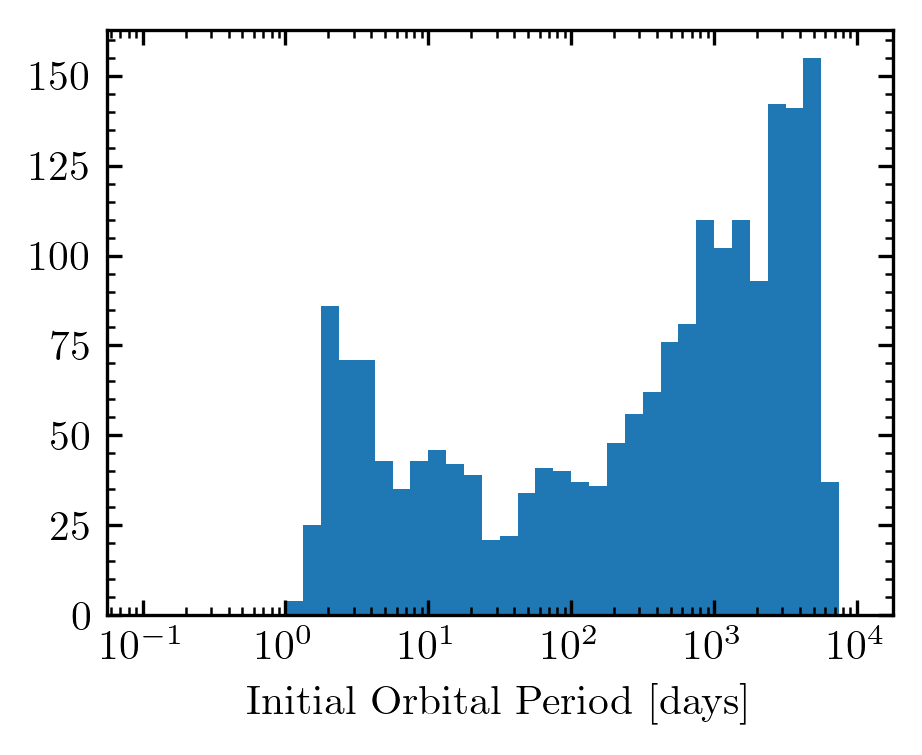

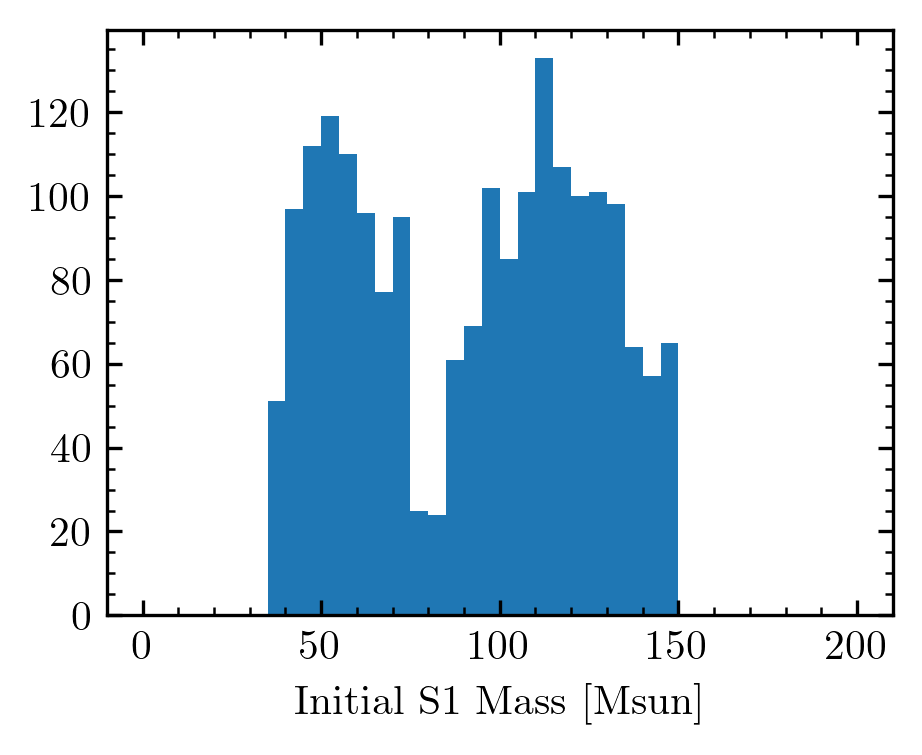

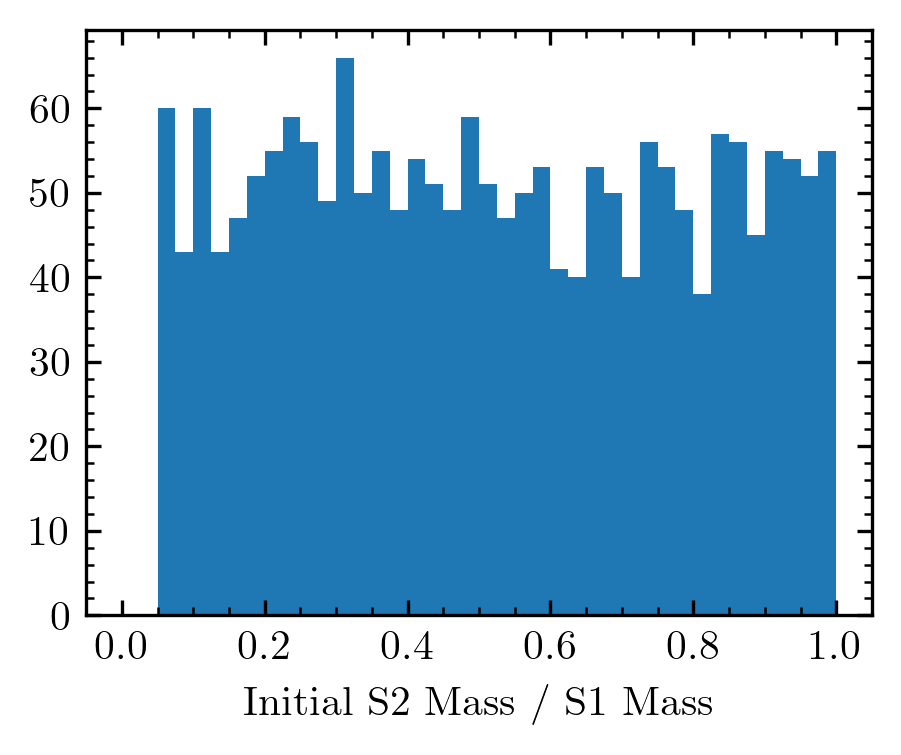

In [33]:
# initial conditions

plt.hist(initial_condition['orbital_period_i'], bins=np.logspace(-1, 4, 41))
plt.xlabel('Initial Orbital Period [days]')
plt.xscale('log')
plt.show()

plt.hist(initial_condition['S1_mass_i'], bins=np.linspace(0, 200, 41))
plt.xlabel('Initial S1 Mass [Msun]')
plt.show()

plt.hist(initial_condition['S2_mass_i']/initial_condition['S1_mass_i'], bins=np.linspace(0, 1, 41))
plt.xlabel('Initial S2 Mass / S1 Mass')
plt.show()

### grid slices

In [34]:
q = 0.8


In [35]:
def plot_grid_slice_for_q(q, ax, grid, oneline_sel, metallicity, marker_colours):
    """
    Plot a grid slice for a specific mass ratio q value.
    
    Parameters
    -----------
    q : float
        Mass ratio (M2/M1) to plot
    ax : matplotlib.axes.Axes
        Axis to plot on
    grid : PSyGrid
        The stellar evolution grid
    oneline_sel : DataFrame
        Selected population data
    metallicity : float
        Metallicity value
    marker_colours : dict
        Dictionary of colors for different markers
    """
    M1_unique = np.unique(grid.initial_values['star_1_mass'])
    
    # Select all binaries with the specified q value
    mask_out = np.isclose(M1_unique[0], grid.initial_values['star_1_mass'], atol=1e-2)
    mask_out = mask_out & np.isclose(grid.initial_values['star_2_mass'], M1_unique[0]*q, atol=1e-2)

    for M1 in M1_unique[1:]:
        mask = np.isclose(M1, grid.initial_values['star_1_mass'], atol=1e-2)
        mask = mask & (np.isclose(grid.initial_values['star_2_mass'], M1*q, atol=1e-2))
        mask_out = mask_out | mask
        
    s_marker = 5

    # Plot no MT cases
    no_MT_mask = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'no_MT')
    if np.any(no_MT_mask):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][no_MT_mask],
                grid.initial_values['period_days'][mask_out][no_MT_mask],
                s=s_marker,
                marker='s',
                facecolor=marker_colours['no_MT'])
        
    # Plot not converged or initial mass transfer
    not_converged_mask = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'not_converged') | \
                         np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'initial_MT')
    if np.any(not_converged_mask):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][not_converged_mask],
                    grid.initial_values['period_days'][mask_out][not_converged_mask],
                    s=2,
                    marker='.',
                    color=marker_colours['not_converged'],
                    linewidth=0.4, label='initial MT or not converged')
    
    # Plot unstable MT
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'unstable_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                    grid.initial_values['period_days'][mask_out][mask_IC],
                    s=s_marker-3,
                    marker='D',
                    color=marker_colours['unstable'],
                    label='unstable MT')
    
    # Plot stable MT cases
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'stable_MT')
    MT_cases = ['case_A', 'case_B', 'case_C', 'contact']
    for case in MT_cases:
        MT_mask = np.char.startswith(grid.final_values['termination_flag_2'][mask_out], case)
        if np.any(mask_IC & MT_mask):
            ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC & MT_mask],
                    grid.initial_values['period_days'][mask_out][mask_IC & MT_mask],
                    s=s_marker,
                    marker='s',
                    facecolor=marker_colours['stable'][case],
                    edgecolor='black',
                    lw=0.1,
                    label=case.replace('_', ' '))
            
    # Plot reverse stable MT
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'stable_reverse_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                grid.initial_values['period_days'][mask_out][mask_IC],
                s=s_marker-2,
                marker='o',
                color=marker_colours['reverse_stable_MT'],
                label='reverse stable MT')
            
    # Plot BBH mergers as contours
    # Z_mask = np.isclose(oneline_sel['metallicity'], metallicity, atol=1e-7)
    # q_mask = np.isclose(oneline_sel['S2_mass_i']/oneline_sel['S1_mass_i'], q, atol=1e-2)
    
    # x = np.linspace(1, 3, 201)
    # y = np.linspace(-1, 4, 201)
    # xi, yi = np.meshgrid(x[:-1], y[:-1])
    
    # h, _, _ = np.histogram2d(np.log10(oneline_sel['S1_mass_i'][Z_mask & q_mask]),
    #                          np.log10(oneline_sel['orbital_period_i'][Z_mask & q_mask]),
    #                          bins=[x, y],
    #                          density=True)
    
    #cs = ax.contour(10**xi, 10**yi, h.T, levels=[0], colors=['black'], alpha=1, zorder=20)
    # from scipy.stats import gaussian_kde
    # data = np.vstack([
    #     np.log10(oneline_sel['S1_mass_i'][Z_mask & q_mask]),
    #     np.log10(oneline_sel['orbital_period_i'][Z_mask & q_mask])
    # ])
    # kde = gaussian_kde(data, bw_method=0.085)
    # zi = kde(np.vstack([xi.flatten(), yi.flatten()]))
    # zi = zi.reshape(xi.shape)
    # ax.contour(10**xi, 10**yi, zi, levels=[kde.factor * 1], colors=['black'], alpha=1, zorder=15, linestyles='-')
    
    
    # Set plot properties
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xticks([20, 30, 50, 100, 200])
    ax.set_xticklabels(['20', '30', '50', '100', '200'])
    
    return ax

Text(0, 0.5, '$P_\\mathrm{ZAMS}$ [days]')

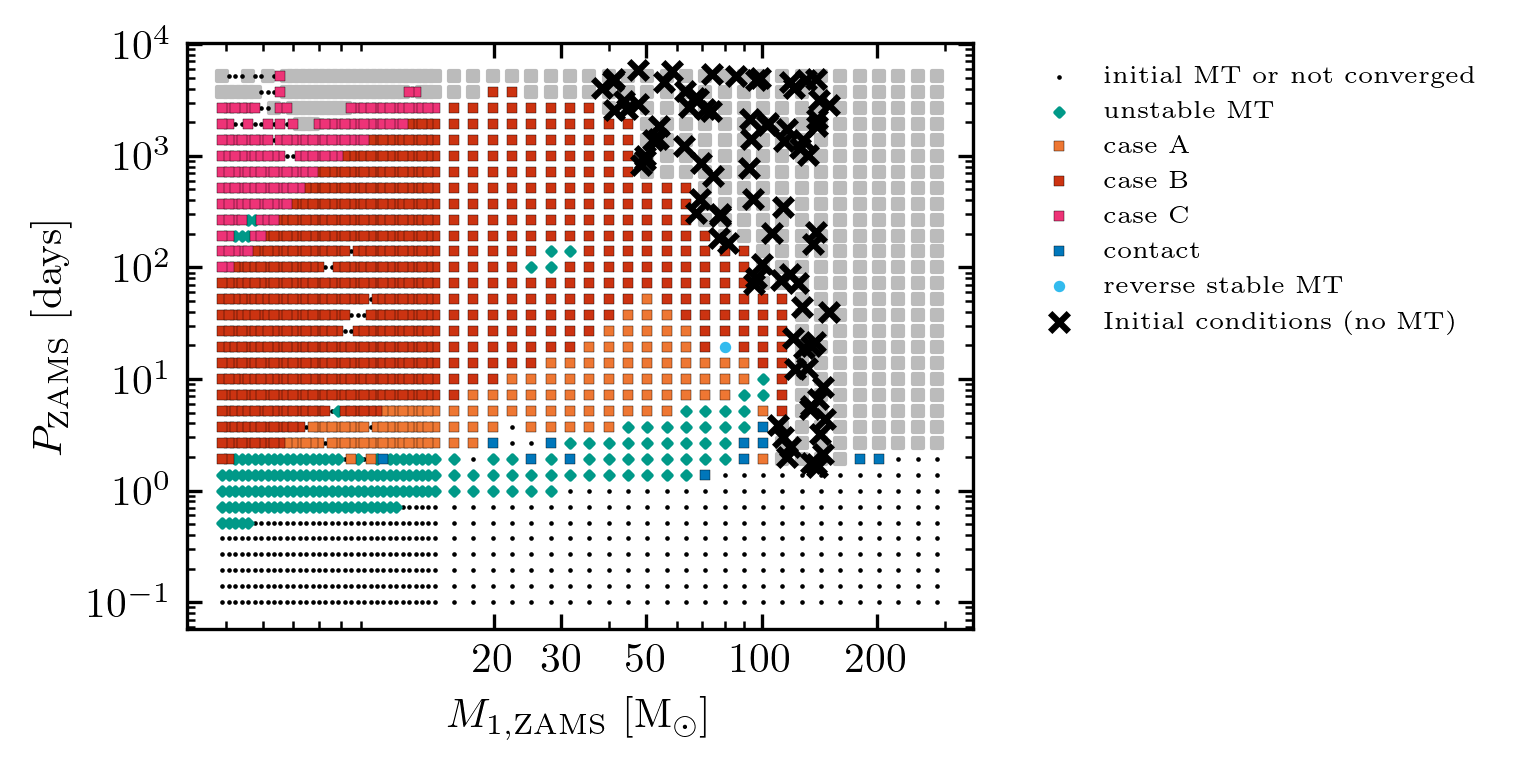

In [36]:
q = 0.8
fig, ax = plt.subplots(figsize=(3.38, 2.535))
oneline_sel = None
metallicity = 1.0
marker_colours = {
    'no_MT': tol_vibrant[6],
    'not_converged': 'black',
    'unstable': tol_vibrant[2],
    'stable': {
        'case_A': tol_vibrant[3],
        'case_B': tol_vibrant[4],
        'case_C': tol_vibrant[5],
        'contact': tol_vibrant[0]
    },
    'reverse_stable_MT': tol_vibrant[1]
}

plot_grid_slice_for_q(q, ax, grid, oneline_sel, metallicity, marker_colours)
q_mask = np.isclose(initial_condition['S2_mass_i']/initial_condition['S1_mass_i'], q, atol=0.025)
plt.scatter(initial_condition['S1_mass_i'][q_mask], initial_condition['orbital_period_i'][q_mask],
            s=20, color='black', marker='x', label='Initial conditions (no MT)')

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6)
plt.xlabel('$M_\mathrm{1,ZAMS}$ [M$_\odot$]')
plt.ylabel('$P_\mathrm{ZAMS}$ [days]')

### example model: short period

In [37]:
mask_m1 = np.isclose(grid.initial_values['star_1_mass'], 90, atol=1)
print(np.sum(mask_m1))
mask_q = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], q, atol=0.025)
print(np.sum(mask_q & mask_m1))
mask_P = np.isclose(grid.initial_values['period_days'], 5, atol=0.5)
print(np.sum(mask_P & mask_q & mask_m1))

example_index = np.where(mask_P & mask_q & mask_m1)[0][0]

680
34
1


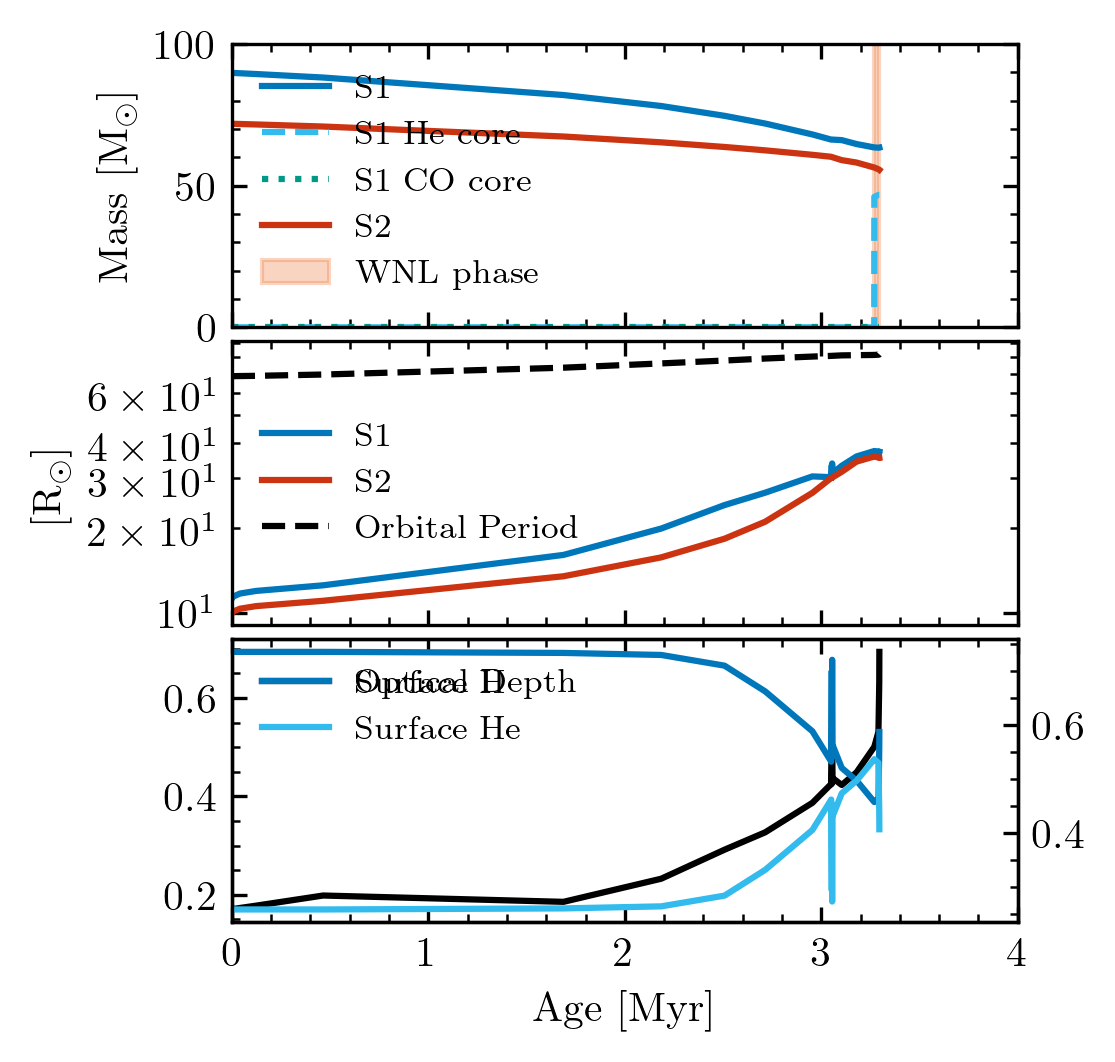

In [38]:
model = grid[example_index]

fig, ax = plt.subplots(3, 1, figsize=(3.38, 2.535*1.5), sharex=True)

x_axis = model.binary_history['age'] / 1e6  # Convert age to Myr

ax[0].plot(x_axis, model.binary_history['star_1_mass'],
           label='S1', color=tol_vibrant[0])
ax[0].plot(x_axis, model.history1['he_core_mass'], label='S1 He core', color=tol_vibrant[1], linestyle='--')
ax[0].plot(x_axis, model.history1['co_core_mass'], label='S1 CO core', color=tol_vibrant[2], linestyle=':')
ax[0].plot(x_axis, model.binary_history['star_2_mass'],
           label='S2', color=tol_vibrant[4])

ax[1].plot(x_axis, 10**model.history1['log_R'], label='S1',
           color=tol_vibrant[0])
ax[1].plot(x_axis, 10**model.history2['log_R'], label='S2', color=tol_vibrant[4])
ax[1].plot(x_axis, model.binary_history['binary_separation'], label='Orbital Period', color='black', linestyle='--')
ax[1].set_yscale('log')

# check when WNL, WNE, WC phases occur based on surface abundances and optical depth
surface_H = model.history1['surface_h1']
surface_He = model.history1['surface_he4']
optical_depth = optical_depth_calculation(model.binary_history['star_1_mass'], 10**model.history1['log_R'], 10**model.history1['log_L'], 10**model.binary_history['lg_wind_mdot_1'], surface_H, surface_He, Teff=10**calc_Teff(model.history1['log_L'], model.history1['log_R']))


# WNL phase: surface H > 0.05, optical depth > 0.5
# not H burning
WNL_mask = (surface_H > 0.05) & (optical_depth > 0.5) & (model.history1['center_h1'] < 0.01)
if np.any(WNL_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNL_mask, color=tol_vibrant[3], alpha=0.3, label='WNL phase')
WNE_mask = (surface_H <= 0.05) & (surface_He >= 0.7) & (optical_depth > 1.5)
if np.any(WNE_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNE_mask, color=tol_vibrant[5], alpha=0.3, label='WNE phase')
WC_mask = (surface_H <= 0.05) & (surface_He < 0.7) & (optical_depth > 1.5)
if np.any(WC_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WC_mask, color=tol_vibrant[4], alpha=0.3, label='WC phase')

# twin y-axis for optical depth and abundances
ax2 = ax[2].twinx()
ax[2].plot(x_axis, optical_depth, label='Optical Depth', color='black')

ax2.plot(x_axis, surface_H, label='Surface H', color=tol_vibrant[0])
ax2.plot(x_axis, surface_He, label='Surface He', color=tol_vibrant[1])
ax2.legend()
ax[2].legend()

plt.subplots_adjust(hspace=0.05)

#ax[0].set_xticklabels([])
ax[0].set_ylim(0, 100)
ax[0].set_xlim(0, 4)
ax[0].legend()
ax[0].set_ylabel('Mass [M$_\odot$]')
ax[1].legend()
ax[1].set_ylabel('[R$_\odot$]')
ax[-1].set_xlabel('Age [Myr]')

plt.show()

### example model: wide period

In [39]:
mask_m1 = np.isclose(grid.initial_values['star_1_mass'], 50, atol=1)
print(np.sum(mask_m1))
mask_q = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], q, atol=0.025)
print(np.sum(mask_q & mask_m1))
mask_P = np.isclose(grid.initial_values['period_days'], 2e3, rtol=0.05)
print(np.sum(mask_P & mask_q & mask_m1))

example_index = np.where(mask_P & mask_q & mask_m1)[0][0]

680
34
1


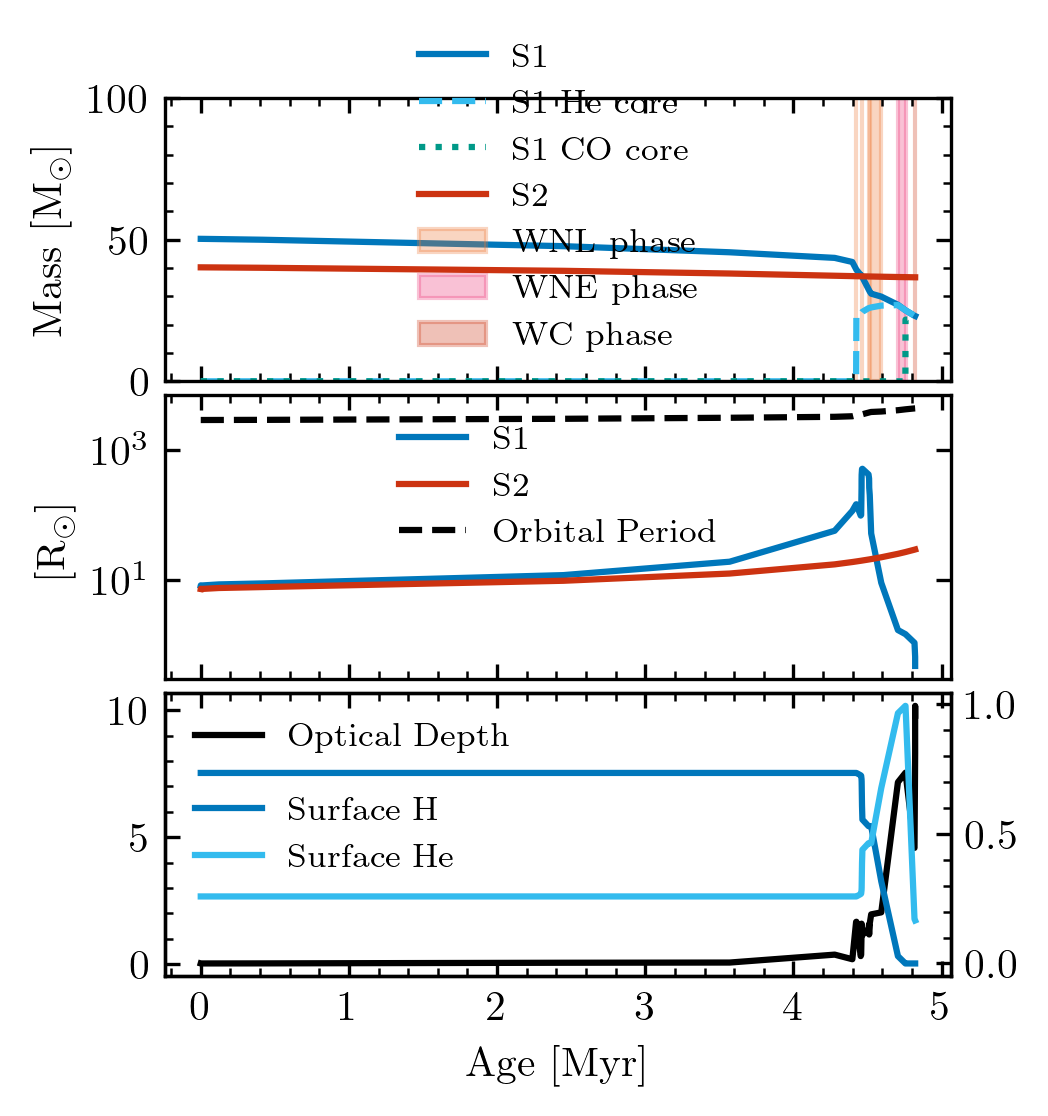

In [40]:
model = grid[example_index]

fig, ax = plt.subplots(3, 1, figsize=(3.38, 2.535*1.5), sharex=True)

x_axis = model.binary_history['age'] / 1e6  # Convert age to Myr

ax[0].plot(x_axis, model.binary_history['star_1_mass'],
           label='S1', color=tol_vibrant[0])
ax[0].plot(x_axis, model.history1['he_core_mass'], label='S1 He core', color=tol_vibrant[1], linestyle='--')
ax[0].plot(x_axis, model.history1['co_core_mass'], label='S1 CO core', color=tol_vibrant[2], linestyle=':')
ax[0].plot(x_axis, model.binary_history['star_2_mass'],
           label='S2', color=tol_vibrant[4])

ax[1].plot(x_axis, 10**model.history1['log_R'], label='S1',
           color=tol_vibrant[0])
ax[1].plot(x_axis, 10**model.history2['log_R'], label='S2', color=tol_vibrant[4])
ax[1].plot(x_axis, model.binary_history['binary_separation'], label='Orbital Period', color='black', linestyle='--')
ax[1].set_yscale('log')

# check when WNL, WNE, WC phases occur based on surface abundances and optical depth
surface_H = model.history1['surface_h1']
surface_He = model.history1['surface_he4']
optical_depth = optical_depth_calculation(model.binary_history['star_1_mass'], 10**model.history1['log_R'], 10**model.history1['log_L'], 10**model.binary_history['lg_wind_mdot_1'], surface_H, surface_He, Teff=10**calc_Teff(model.history1['log_L'], model.history1['log_R']))


# WNL phase: surface H > 0.05, optical depth > 0.5
# not H burning
WNL_mask = (surface_H > 0.05) & (optical_depth > 1.5) & (model.history1['center_h1'] < 0.01)
if np.any(WNL_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNL_mask, color=tol_vibrant[3], alpha=0.3, label='WNL phase')
WNE_mask = (surface_H <= 0.05) & (surface_He >= 0.7) & (optical_depth > 1.5)
if np.any(WNE_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNE_mask, color=tol_vibrant[5], alpha=0.3, label='WNE phase')
WC_mask = (surface_H <= 0.05) & (surface_He < 0.7) & (optical_depth > 1.5)
if np.any(WC_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WC_mask, color=tol_vibrant[4], alpha=0.3, label='WC phase')

# twin y-axis for optical depth and abundances
ax2 = ax[2].twinx()
ax[2].plot(x_axis, optical_depth, label='Optical Depth', color='black')

ax2.plot(x_axis, surface_H, label='Surface H', color=tol_vibrant[0])
ax2.plot(x_axis, surface_He, label='Surface He', color=tol_vibrant[1])
ax2.legend()
ax[2].legend()

plt.subplots_adjust(hspace=0.05)

#ax[0].set_xticklabels([])
ax[0].set_ylim(0, 100)
#ax[0].set_xlim(0, 4)
ax[0].legend()
ax[0].set_ylabel('Mass [M$_\odot$]')
ax[1].legend()
ax[1].set_ylabel('[R$_\odot$]')
ax[-1].set_xlabel('Age [Myr]')

plt.show()

## Interacting systems


In [41]:
initial_condition = pop.oneline[np.unique(key_array[mask_stable & WNE])]

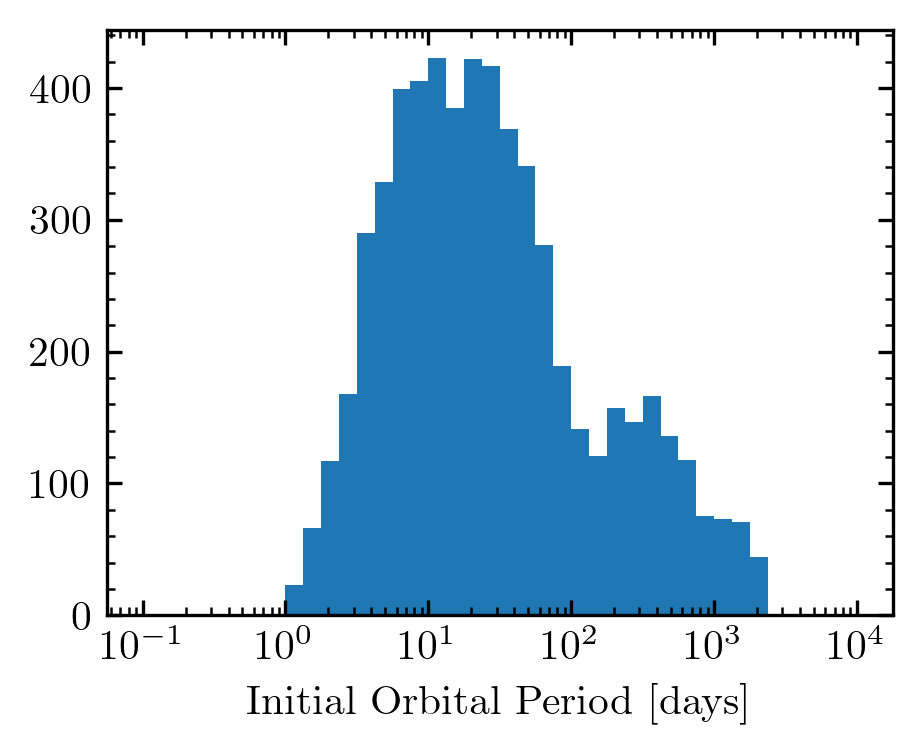

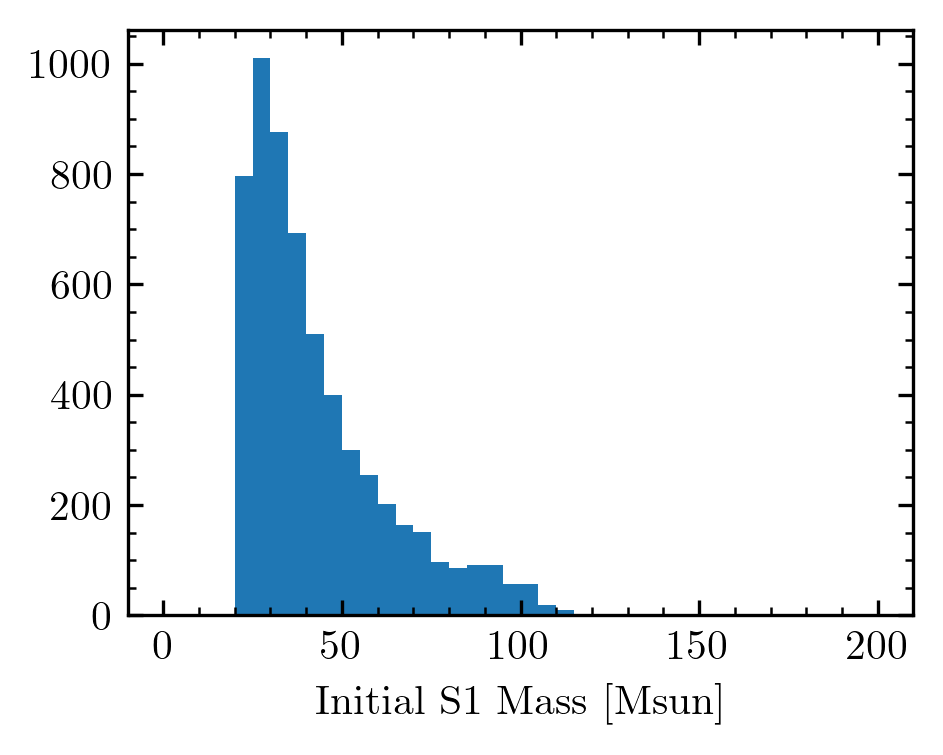

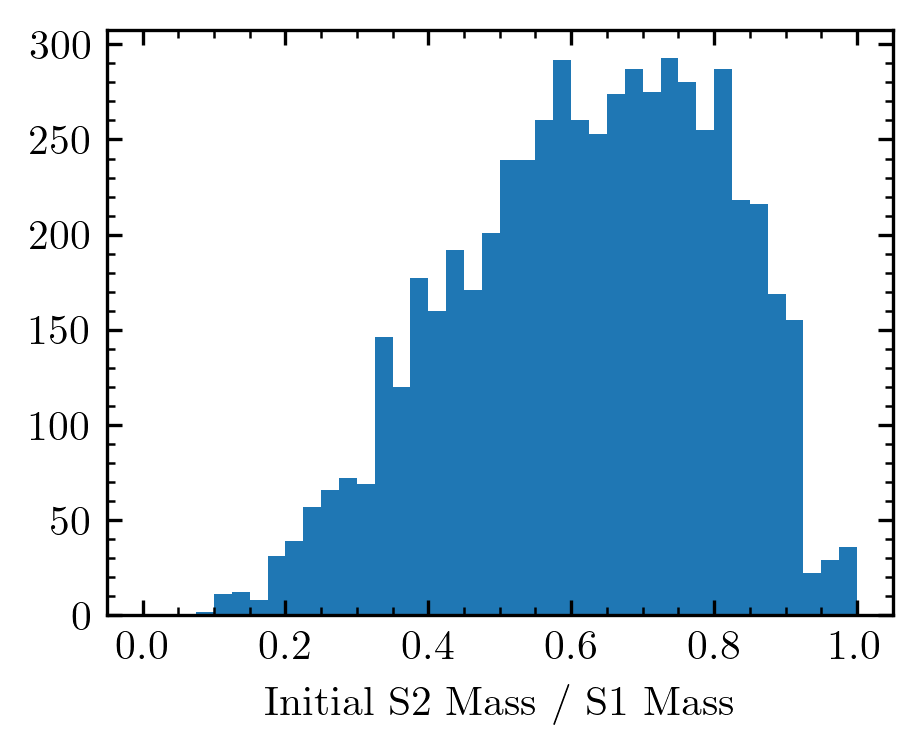

In [42]:
# initial conditions

plt.hist(initial_condition['orbital_period_i'], bins=np.logspace(-1, 4, 41))
plt.xlabel('Initial Orbital Period [days]')
plt.xscale('log')
plt.show()

plt.hist(initial_condition['S1_mass_i'], bins=np.linspace(0, 200, 41))
plt.xlabel('Initial S1 Mass [Msun]')
plt.show()

plt.hist(initial_condition['S2_mass_i']/initial_condition['S1_mass_i'], bins=np.linspace(0, 1, 41))
plt.xlabel('Initial S2 Mass / S1 Mass')
plt.show()

### grid slices

In [43]:
q = 0.8


In [44]:
def plot_grid_slice_for_q(q, ax, grid, oneline_sel, metallicity, marker_colours):
    """
    Plot a grid slice for a specific mass ratio q value.
    
    Parameters
    -----------
    q : float
        Mass ratio (M2/M1) to plot
    ax : matplotlib.axes.Axes
        Axis to plot on
    grid : PSyGrid
        The stellar evolution grid
    oneline_sel : DataFrame
        Selected population data
    metallicity : float
        Metallicity value
    marker_colours : dict
        Dictionary of colors for different markers
    """
    M1_unique = np.unique(grid.initial_values['star_1_mass'])
    
    # Select all binaries with the specified q value
    mask_out = np.isclose(M1_unique[0], grid.initial_values['star_1_mass'], atol=1e-2)
    mask_out = mask_out & np.isclose(grid.initial_values['star_2_mass'], M1_unique[0]*q, atol=1e-2)

    for M1 in M1_unique[1:]:
        mask = np.isclose(M1, grid.initial_values['star_1_mass'], atol=1e-2)
        mask = mask & (np.isclose(grid.initial_values['star_2_mass'], M1*q, atol=1e-2))
        mask_out = mask_out | mask
        
    s_marker = 5

    # Plot no MT cases
    no_MT_mask = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'no_MT')
    if np.any(no_MT_mask):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][no_MT_mask],
                grid.initial_values['period_days'][mask_out][no_MT_mask],
                s=s_marker,
                marker='s',
                facecolor=marker_colours['no_MT'])
        
    # Plot not converged or initial mass transfer
    not_converged_mask = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'not_converged') | \
                         np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'initial_MT')
    if np.any(not_converged_mask):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][not_converged_mask],
                    grid.initial_values['period_days'][mask_out][not_converged_mask],
                    s=2,
                    marker='.',
                    color=marker_colours['not_converged'],
                    linewidth=0.4, label='initial MT or not converged')
    
    # Plot unstable MT
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'unstable_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                    grid.initial_values['period_days'][mask_out][mask_IC],
                    s=s_marker-3,
                    marker='D',
                    color=marker_colours['unstable'],
                    label='unstable MT')
    
    # Plot stable MT cases
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'stable_MT')
    MT_cases = ['case_A', 'case_B', 'case_C', 'contact']
    for case in MT_cases:
        MT_mask = np.char.startswith(grid.final_values['termination_flag_2'][mask_out], case)
        if np.any(mask_IC & MT_mask):
            ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC & MT_mask],
                    grid.initial_values['period_days'][mask_out][mask_IC & MT_mask],
                    s=s_marker,
                    marker='s',
                    facecolor=marker_colours['stable'][case],
                    edgecolor='black',
                    lw=0.1,
                    label=case.replace('_', ' '))
            
    # Plot reverse stable MT
    mask_IC = np.char.startswith(grid.final_values['interpolation_class'][mask_out], 'stable_reverse_MT')
    if np.any(mask_IC):
        ax.scatter(grid.initial_values['star_1_mass'][mask_out][mask_IC],
                grid.initial_values['period_days'][mask_out][mask_IC],
                s=s_marker-2,
                marker='o',
                color=marker_colours['reverse_stable_MT'],
                label='reverse stable MT')
            
    # Plot BBH mergers as contours
    # Z_mask = np.isclose(oneline_sel['metallicity'], metallicity, atol=1e-7)
    # q_mask = np.isclose(oneline_sel['S2_mass_i']/oneline_sel['S1_mass_i'], q, atol=1e-2)
    
    # x = np.linspace(1, 3, 201)
    # y = np.linspace(-1, 4, 201)
    # xi, yi = np.meshgrid(x[:-1], y[:-1])
    
    # h, _, _ = np.histogram2d(np.log10(oneline_sel['S1_mass_i'][Z_mask & q_mask]),
    #                          np.log10(oneline_sel['orbital_period_i'][Z_mask & q_mask]),
    #                          bins=[x, y],
    #                          density=True)
    
    #cs = ax.contour(10**xi, 10**yi, h.T, levels=[0], colors=['black'], alpha=1, zorder=20)
    # from scipy.stats import gaussian_kde
    # data = np.vstack([
    #     np.log10(oneline_sel['S1_mass_i'][Z_mask & q_mask]),
    #     np.log10(oneline_sel['orbital_period_i'][Z_mask & q_mask])
    # ])
    # kde = gaussian_kde(data, bw_method=0.085)
    # zi = kde(np.vstack([xi.flatten(), yi.flatten()]))
    # zi = zi.reshape(xi.shape)
    # ax.contour(10**xi, 10**yi, zi, levels=[kde.factor * 1], colors=['black'], alpha=1, zorder=15, linestyles='-')
    
    
    # Set plot properties
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xticks([20, 30, 50, 100, 200])
    ax.set_xticklabels(['20', '30', '50', '100', '200'])
    
    return ax

Text(0, 0.5, '$P_\\mathrm{ZAMS}$ [days]')

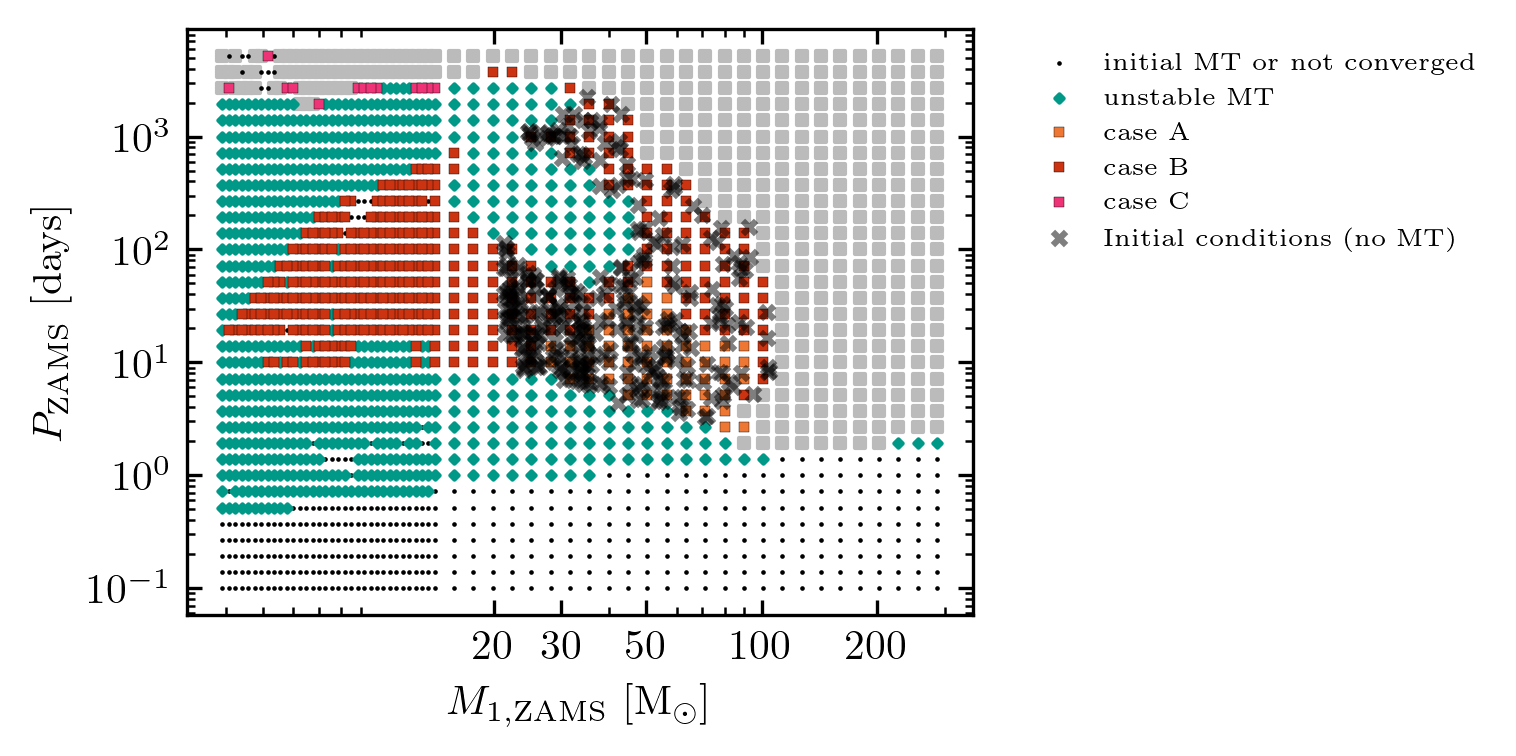

In [47]:
q = 0.4
fig, ax = plt.subplots(figsize=(3.38, 2.535))
oneline_sel = None
metallicity = 1.0
marker_colours = {
    'no_MT': tol_vibrant[6],
    'not_converged': 'black',
    'unstable': tol_vibrant[2],
    'stable': {
        'case_A': tol_vibrant[3],
        'case_B': tol_vibrant[4],
        'case_C': tol_vibrant[5],
        'contact': tol_vibrant[0]
    },
    'reverse_stable_MT': tol_vibrant[1]
}

plot_grid_slice_for_q(q, ax, grid, oneline_sel, metallicity, marker_colours)
q_mask = np.isclose(initial_condition['S2_mass_i']/initial_condition['S1_mass_i'], q, atol=0.025)
plt.scatter(initial_condition['S1_mass_i'][q_mask], initial_condition['orbital_period_i'][q_mask],
            s=10, color='black', marker='x', label='Initial conditions (no MT)', alpha=0.5)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6)
plt.xlabel('$M_\mathrm{1,ZAMS}$ [M$_\odot$]')
plt.ylabel('$P_\mathrm{ZAMS}$ [days]')

In [48]:
mask_m1 = np.isclose(grid.initial_values['star_1_mass'], 50, atol=1)
print(np.sum(mask_m1))
mask_q = np.isclose(grid.initial_values['star_2_mass']/grid.initial_values['star_1_mass'], q, atol=0.025)
print(np.sum(mask_q & mask_m1))
mask_P = np.isclose(grid.initial_values['period_days'], 10, rtol=0.05)
print(np.sum(mask_P & mask_q & mask_m1))

example_index = np.where(mask_P & mask_q & mask_m1)[0][0]



680
34
1


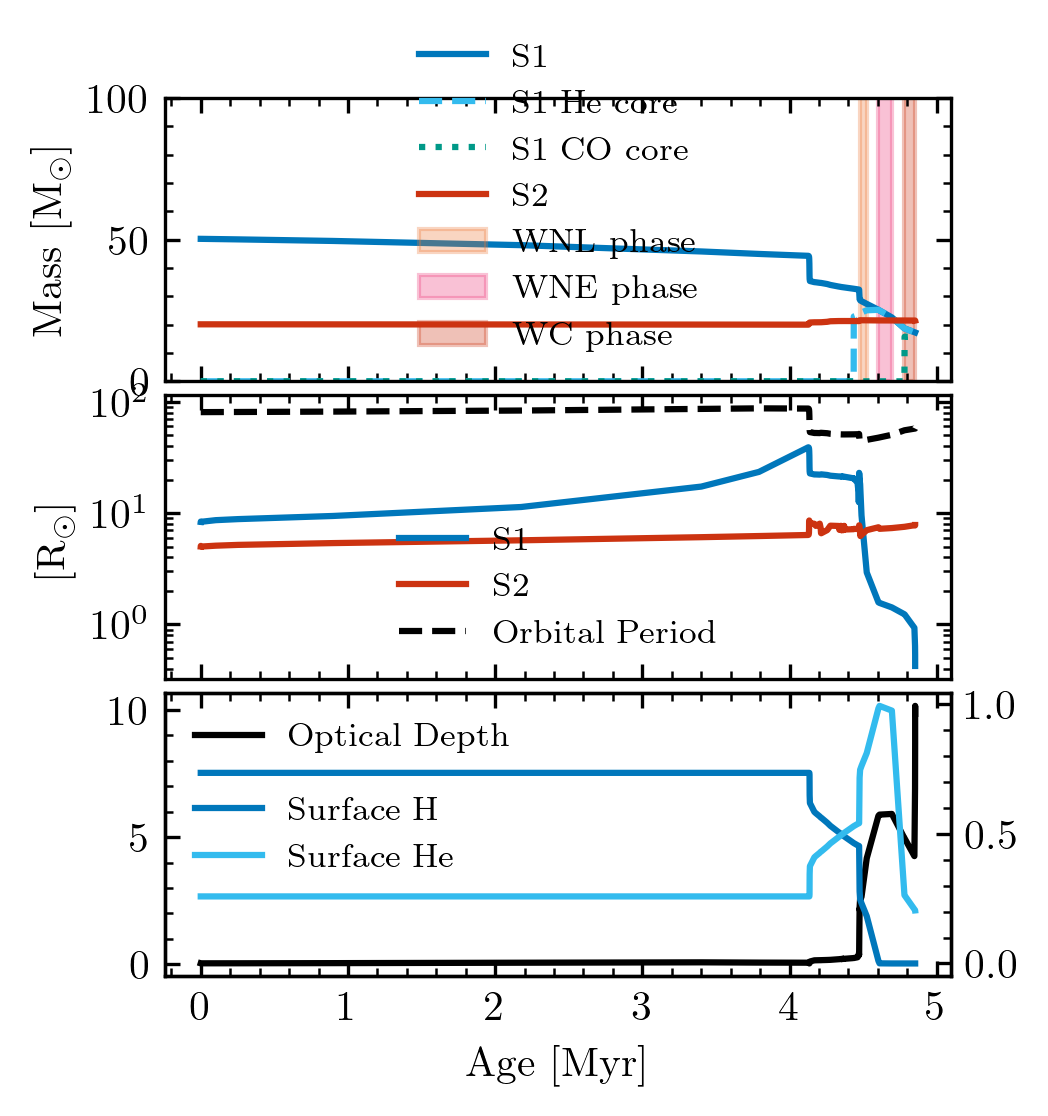

In [49]:
model = grid[example_index]

fig, ax = plt.subplots(3, 1, figsize=(3.38, 2.535*1.5), sharex=True)

x_axis = model.binary_history['age'] / 1e6  # Convert age to Myr

ax[0].plot(x_axis, model.binary_history['star_1_mass'],
           label='S1', color=tol_vibrant[0])
ax[0].plot(x_axis, model.history1['he_core_mass'], label='S1 He core', color=tol_vibrant[1], linestyle='--')
ax[0].plot(x_axis, model.history1['co_core_mass'], label='S1 CO core', color=tol_vibrant[2], linestyle=':')
ax[0].plot(x_axis, model.binary_history['star_2_mass'],
           label='S2', color=tol_vibrant[4])

ax[1].plot(x_axis, 10**model.history1['log_R'], label='S1',
           color=tol_vibrant[0])
ax[1].plot(x_axis, 10**model.history2['log_R'], label='S2', color=tol_vibrant[4])
ax[1].plot(x_axis, model.binary_history['binary_separation'], label='Orbital Period', color='black', linestyle='--')
ax[1].set_yscale('log')

# check when WNL, WNE, WC phases occur based on surface abundances and optical depth
surface_H = model.history1['surface_h1']
surface_He = model.history1['surface_he4']
optical_depth = optical_depth_calculation(model.binary_history['star_1_mass'], 10**model.history1['log_R'], 10**model.history1['log_L'], 10**model.binary_history['lg_wind_mdot_1'], surface_H, surface_He, Teff=10**calc_Teff(model.history1['log_L'], model.history1['log_R']))


# WNL phase: surface H > 0.05, optical depth > 0.5
# not H burning
WNL_mask = (surface_H > 0.05) & (optical_depth > 1.5) & (model.history1['center_h1'] < 0.01)
if np.any(WNL_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNL_mask, color=tol_vibrant[3], alpha=0.3, label='WNL phase')
WNE_mask = (surface_H <= 0.05) & (surface_He >= 0.7) & (optical_depth > 1.5)
if np.any(WNE_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WNE_mask, color=tol_vibrant[5], alpha=0.3, label='WNE phase')
WC_mask = (surface_H <= 0.05) & (surface_He < 0.7) & (optical_depth > 1.5)
if np.any(WC_mask):
    ax[0].fill_between(x_axis, 0, 100, where=WC_mask, color=tol_vibrant[4], alpha=0.3, label='WC phase')

# twin y-axis for optical depth and abundances
ax2 = ax[2].twinx()
ax[2].plot(x_axis, optical_depth, label='Optical Depth', color='black')

ax2.plot(x_axis, surface_H, label='Surface H', color=tol_vibrant[0])
ax2.plot(x_axis, surface_He, label='Surface He', color=tol_vibrant[1])
ax2.legend()
ax[2].legend()

plt.subplots_adjust(hspace=0.05)

#ax[0].set_xticklabels([])
ax[0].set_ylim(0, 100)
#ax[0].set_xlim(0, 4)
ax[0].legend()
ax[0].set_ylabel('Mass [M$_\odot$]')
ax[1].legend()
ax[1].set_ylabel('[R$_\odot$]')
ax[-1].set_xlabel('Age [Myr]')

plt.show()